In [1]:
import numpy as np
import torch
import algorithms.kernelDL_multistep as kdl
from algorithms.dmd import rffEDMD
import scipy.io as sio
import matplotlib.pyplot as plt

import utils.kernels as kernels
import utils.helpers as helpers
import utils.plotting_params

# koopmanAE
from koopmanAE.model import koopmanAE
from koopmanAE.train import train
from koopmanAE.tools import *

# sindy-shred
import sys, os
sys.path.append(os.path.abspath('../sindy-shred'))
from sindy_shred import SINDySHRED
from sindy_shred.processdata import load_data
from sindy_shred import plotting

%load_ext autoreload
%autoreload 2

Connected to a GPU


###  load data

In [2]:
SST = sio.loadmat('data/SST_data.mat')['Z']
print(f"Shape of the full data: {SST.shape}")
# SST locations
sst_idx = np.where(~np.all(np.isclose(SST, 0.), axis=1))[0]

# Subset the SST data
SST = SST[sst_idx, :]
print(f"Shape of SST data: {SST.shape}")

# find rows that are constant over the training period and remove them
T = 1000
constant_rows = np.all(np.isclose(SST[:, :T], SST[:, 0:1]), axis=1)
SST_f = SST[~constant_rows, :]
print(f"Shape of SST data after removing constant rows: {SST.shape}")
print(f"Number of constant rows removed: {constant_rows.sum()}")

# train/test split
SST_train, SST_test = SST_f[:, :T], SST_f[:, T:]

Shape of the full data: (64800, 1400)
Shape of SST data: (44219, 1400)
Shape of SST data after removing constant rows: (44219, 1400)
Number of constant rows removed: 720


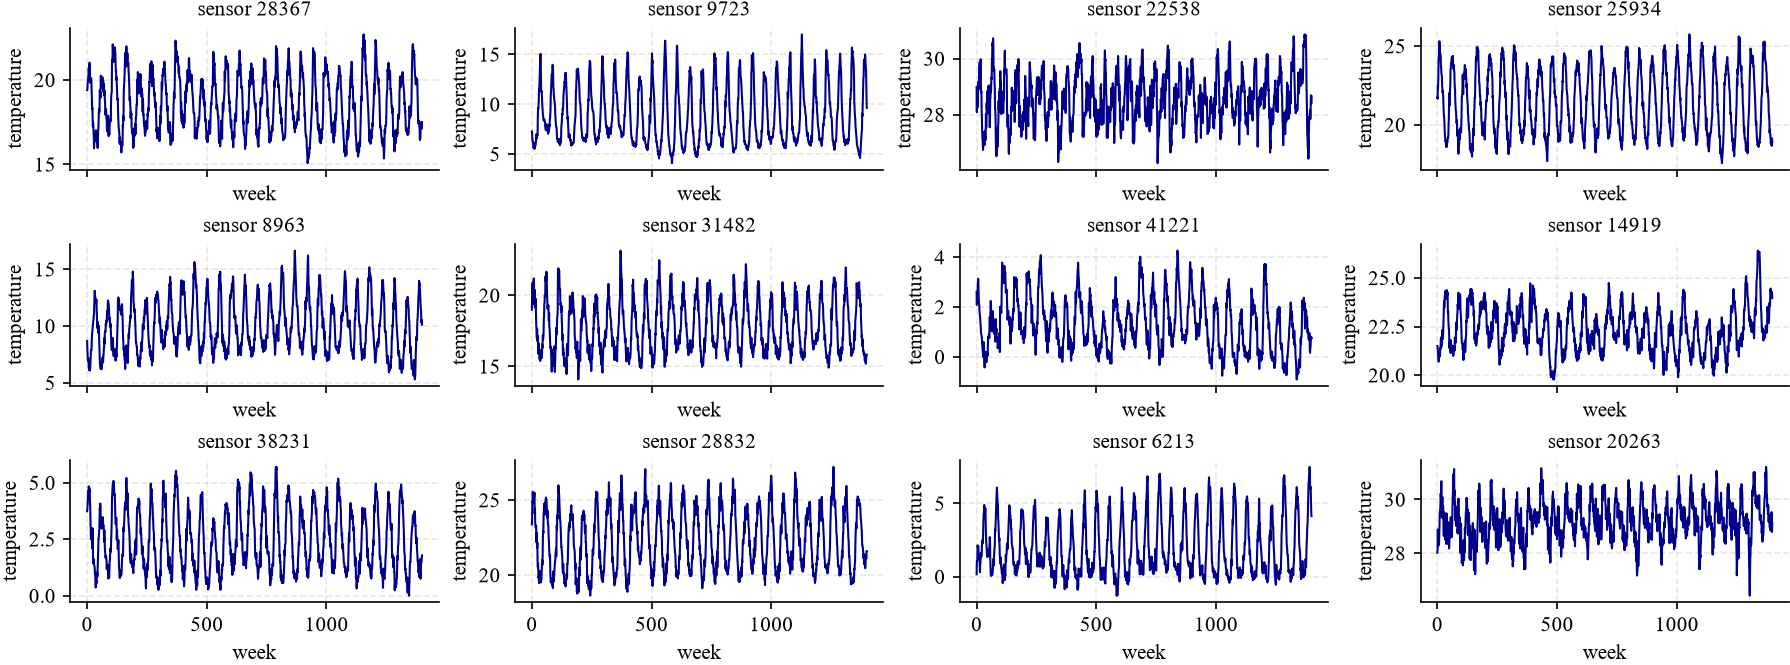

In [3]:
nrow, ncol = 3, 4
idx = np.random.choice(SST.shape[0], nrow * ncol, replace=False)
fig, ax = plt.subplots(nrow, ncol, figsize=(ncol*3, nrow*1.5), sharex=True, constrained_layout=True)
ax = ax.flatten()
for i, j in enumerate(idx):
    ax[i].plot(SST[j, :], color='darkblue', lw=1)
    ax[i].set_title(f'sensor {j+1}')
    ax[i].set_xlabel('week')
    ax[i].set_ylabel('temperature')
plt.show()

**pre-process training data**

In [4]:
# scale the SST data
SST_train_scaled = (SST_train - SST_train.min(axis=1, keepdims=True)) / np.ptp(SST_train, axis=1, keepdims=True)
SST_test_scaled = (SST_test - SST_train.min(axis=1, keepdims=True)) / np.ptp(SST_train, axis=1, keepdims=True)
# SVD
U, S, VT = np.linalg.svd(SST_train_scaled, full_matrices=False)

In [5]:
cum_energy = np.cumsum(S[1:]**2) / np.sum(S[1:]**2)
threshold = 0.9
r = np.searchsorted(cum_energy, threshold) + 1
print(f"Number of modes to retain {r} to capture {threshold*100}% of the energy")

Number of modes to retain 19 to capture 90.0% of the energy


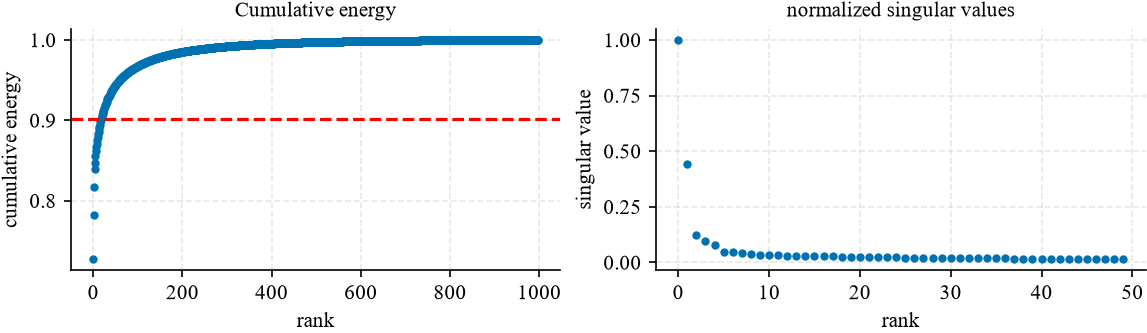

In [6]:
fig = plt.figure(figsize=(8, 2.5))
fig.add_subplot(1, 2, 1)
plt.plot(cum_energy,'.')
plt.axhline(cum_energy[r-1], color='r', ls='--')
plt.xlabel('rank')
plt.ylabel('cumulative energy')
plt.title('Cumulative energy')


fig.add_subplot(1, 2, 2)
plt.plot(S[:50]/S[0],'.')
plt.title('normalized singular values')
plt.xlabel('rank')
plt.ylabel('singular value')
plt.tight_layout()
plt.show()

**dimensionality reduction**

In [7]:
Xtrain, Xtest = U[:, :r].T @ SST_train_scaled, U[:, :r].T @ SST_test_scaled

# scale training data
Xtrain_scaled = (Xtrain - Xtrain.min(axis=1, keepdims=True)) / np.ptp(Xtrain, axis=1, keepdims=True)
X, Y = Xtrain_scaled[:, :-1], Xtrain_scaled[:, 1:]

# scale test data
Xtest_scaled = (Xtest - Xtrain.min(axis=1, keepdims=True)) / np.ptp(Xtrain, axis=1, keepdims=True)

### cKAE

In [8]:
steps, steps_back, backward, epochs = 8, 8, 1, 1000   # koopmanAE
dim = X.shape[0]
embed_dim = 8

In [9]:
seed = 0
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.cuda.manual_seed(seed)
torch.manual_seed(seed)
np.random.seed(seed)
set_seed(seed)
device = get_device()

batchsize=100; init_scale=0.99; alpha_=3
lr=1e-2; wd=0; lamb=1; lr_decay=0.2; lr_update=[50, 200] + [300 + 100*i for i in range(6)];
nu=1e-1; eta=1e-2; gradclip=0.05; 


#****************************************************************
#     prepare dataset for koopmanAE
#****************************************************************
X_train_kae = add_channels(Xtrain_scaled.T)

# create dataloader
X_train_kae = torch.from_numpy(X_train_kae).float().contiguous()
trainDat = []
start = 0
for i in np.arange(steps,-1, -1):
    if i == 0:
        trainDat.append(X_train_kae[start:].float())
    else:
        trainDat.append(X_train_kae[start:-i].float())
    start += 1

train_data = torch.utils.data.TensorDataset(*trainDat)
del(trainDat)

train_loader = torch.utils.data.DataLoader(dataset = train_data, batch_size = batchsize, shuffle = True)

#*************************************************************
#             Model
#*************************************************************
model_ckae = koopmanAE(dim, 1, embed_dim, steps, steps_back, alpha_, init_scale)
model_ckae = model_ckae.to(device)

print('**** Setup ****')
print('Total params: %.2fM' % (sum(p.numel() for p in model_ckae.parameters())/1000000.0))
print('Total params: %.2fk' % (sum(p.numel() for p in model_ckae.parameters())/1000.0))
print('************')
print(model_ckae)

#==============================================================================
# Training
#==============================================================================
model, optimizer, epoch_hist = train(model_ckae, train_loader, lr=lr, weight_decay=wd, lamb=lamb, num_epochs = epochs,
                    learning_rate_change=lr_decay, epoch_update=lr_update,nu = nu, eta = eta, backward=backward,
                    steps=steps, steps_back=steps_back, gradclip=gradclip)

Connected to a GPU
**** Setup ****
Total params: 0.01M
Total params: 7.55k
************
koopmanAE(
  (encoder): encoderNet(
    (tanh): Tanh()
    (fc1): Linear(in_features=19, out_features=48, bias=True)
    (fc2): Linear(in_features=48, out_features=48, bias=True)
    (fc3): Linear(in_features=48, out_features=8, bias=True)
  )
  (dynamics): dynamics(
    (dynamics): Linear(in_features=8, out_features=8, bias=False)
  )
  (backdynamics): dynamics_back(
    (dynamics): Linear(in_features=8, out_features=8, bias=False)
  )
  (decoder): decoderNet(
    (tanh): Tanh()
    (fc1): Linear(in_features=8, out_features=48, bias=True)
    (fc2): Linear(in_features=48, out_features=48, bias=True)
    (fc3): Linear(in_features=48, out_features=19, bias=True)
  )
)
Connected to a GPU
********** Epoche 1 **********
loss identity:  0.29161372780799866
loss backward:  0.3659246265888214
loss consistent:  5.354146480560303
loss forward:  0.3551875054836273
loss sum:  0.7369351983070374
********** Epoc

### KAE

In [10]:
seed = 0
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.cuda.manual_seed(seed)
torch.manual_seed(seed)
np.random.seed(seed)
set_seed(seed)

#*************************************************************
#             Model
#*************************************************************
nu=0.0; eta=0.0; backward=0; steps_back=0,
model_kae = koopmanAE(dim, 1, embed_dim, steps, steps_back, alpha_, init_scale)
model_kae = model_kae.to(device)

print('**** Setup ****')
print('Total params: %.2fM' % (sum(p.numel() for p in model_kae.parameters())/1000000.0))
print('Total params: %.2fk' % (sum(p.numel() for p in model_kae.parameters())/1000.0))
print('************')
print(model_kae)

#==============================================================================
# Training
#==============================================================================
model_kae, optimizer, epoch_hist = train(model_kae, train_loader, lr=lr, weight_decay=wd, lamb=lamb, num_epochs = epochs,
                    learning_rate_change=lr_decay, epoch_update=lr_update,nu = nu, eta = eta, backward=backward,
                    steps=steps, steps_back=steps_back, gradclip=gradclip)

**** Setup ****
Total params: 0.01M
Total params: 7.55k
************
koopmanAE(
  (encoder): encoderNet(
    (tanh): Tanh()
    (fc1): Linear(in_features=19, out_features=48, bias=True)
    (fc2): Linear(in_features=48, out_features=48, bias=True)
    (fc3): Linear(in_features=48, out_features=8, bias=True)
  )
  (dynamics): dynamics(
    (dynamics): Linear(in_features=8, out_features=8, bias=False)
  )
  (backdynamics): dynamics_back(
    (dynamics): Linear(in_features=8, out_features=8, bias=False)
  )
  (decoder): decoderNet(
    (tanh): Tanh()
    (fc1): Linear(in_features=8, out_features=48, bias=True)
    (fc2): Linear(in_features=48, out_features=48, bias=True)
    (fc3): Linear(in_features=48, out_features=19, bias=True)
  )
)
Connected to a GPU
********** Epoche 1 **********
loss identity:  0.2883112132549286
loss forward:  0.3588326573371887
loss sum:  0.6471438407897949
********** Epoche 21 **********
loss identity:  0.09948812425136566
loss forward:  0.16060148179531097
los

### EDMD-kDL

In [11]:
# generate collocation points
seed = 42
dim = X.shape[0]
mc, seed = 8, 42
l_bounds = [X.min() -1.]*dim 
u_bounds = [X.max() + 1.]*dim 
Z = helpers.generate_collocation_points(dim, l_bounds, u_bounds, m=mc, seed=seed).T

In [12]:
fixed_feature_fn = lambda x: x

In [76]:
sigma, p, gamma = 10., dim*2, 1e-6
kernel = kernels.gaussianKernel(sigma=sigma)

edmd_kdl = kdl.EDMDkDL(X=X, Y=Y, Z=Z, kernel=kernel, p=p, gamma=gamma,  decoder=True, fixed_feature_fn=fixed_feature_fn, rcond=None)    

In [77]:
edmd_kdl.optimize(n_iters=1000, steps=8, beta1=1, beta2=1., beta3=1e-6, verbose_after=20, history_size=50)

step   0 | loss 5.5e+12
step  20 | loss 4.6e+00
step  40 | loss 2.4e-02
step  60 | loss 1.6e-02
step  80 | loss 9.9e-03
step 100 | loss 6.6e-03
step 120 | loss 4.7e-03
step 140 | loss 3.5e-03
step 160 | loss 2.6e-03
step 180 | loss 2.1e-03
step 200 | loss 1.7e-03
step 220 | loss 1.4e-03
step 240 | loss 1.2e-03
step 260 | loss 1.0e-03
step 280 | loss 8.7e-04
step 300 | loss 7.6e-04
step 320 | loss 6.8e-04
step 340 | loss 6.2e-04
step 360 | loss 5.6e-04
step 380 | loss 5.2e-04
step 400 | loss 4.7e-04
step 420 | loss 4.3e-04
step 440 | loss 3.9e-04
step 460 | loss 3.5e-04
step 480 | loss 3.2e-04
step 500 | loss 2.9e-04
step 520 | loss 2.7e-04
step 540 | loss 2.5e-04
step 560 | loss 2.3e-04
step 580 | loss 2.2e-04
step 600 | loss 2.1e-04
step 620 | loss 1.9e-04
step 640 | loss 1.8e-04
step 660 | loss 1.7e-04
step 680 | loss 1.6e-04
step 700 | loss 1.5e-04
step 720 | loss 1.4e-04
step 740 | loss 1.3e-04
step 760 | loss 1.3e-04
step 780 | loss 1.2e-04
step 800 | loss 1.2e-04
step 820 | loss 

### EDMD-RFF

In [16]:
edmd_rff = rffEDMD(X, Y, sigma=sigma, decoder=True, rcond=None)
edmd_rff.train(n_features=100)

**plot eigenvalues**

In [78]:
# cKAE
K_ckae = model_ckae.dynamics.dynamics.weight.data.detach().cpu().numpy()
K_kae = model_kae.dynamics.dynamics.weight.data.detach().cpu().numpy()
eigvals_ckae = np.linalg.eigvals(K_ckae)
eigvals_kae = np.linalg.eigvals(K_kae)
eigvals_edmdkdl = edmd_kdl.eigvals
eigvals_edmdrff = np.linalg.eigvals(edmd_rff.K)

EigVals = [eigvals_edmdrff, eigvals_kae, eigvals_ckae, eigvals_edmdkdl]
labels = ['EDMD-RFF', 'KAE', 'cKAE', 'EDMD-kDL']
colors_list = ['magenta', 'orange', 'darkred', 'darkblue']

fig, axes = plt.subplots(1, len(EigVals), figsize=(5.5, 1.6), constrained_layout=True)

theta = np.linspace(0, 2*np.pi, 200)
unit_circle = np.column_stack([np.cos(theta), np.sin(theta)])

# consistent limits across all panels, based on global max |eigval|
max_extent = max(np.max(np.abs(ev)) for ev in EigVals)
lim = max(1.1, max_extent * 1.1)  # pad beyond unit circle / data, whichever is larger

for i, (ax, eigvals) in enumerate(zip(axes, EigVals)):
    ax.plot(unit_circle[:, 0], unit_circle[:, 1], color='gray', ls='--', lw=0.6, zorder=1)
    ax.vlines(0, -1, 1, color='gray', ls='--', lw=0.2)
    ax.hlines(0, -1, 1, color='gray', ls='--', lw=0.2)
    ax.scatter(eigvals.real, eigvals.imag, color=colors_list[i], s=5, linewidths=0,
               zorder=2, clip_on=False)

    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_aspect('equal')
    ax.set_title(labels[i], fontsize=12, pad=3)
    ax.set_xlabel(r'Re($\lambda$)', fontsize=12)
    ax.tick_params(labelsize=12, length=2)

    if i == 0:
        ax.set_ylabel(r'Im($\lambda$)', fontsize=12)
    else:
        ax.set_yticklabels([])  

    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    ax.grid(False)

fig.savefig('figures/sst_eigvals.pdf', bbox_inches='tight')
plt.close(fig)

### predictions in reduced space

In [79]:
lag = 82  # to match sindy-shred prediction horizon
M = Xtest.shape[1] - lag
x0 = Xtest_scaled[:,lag]
x0_kae = torch.from_numpy(add_channels(Xtest_scaled.T)[lag]).contiguous().float()

In [80]:
# kae
with torch.no_grad():
    z0 = model_kae.encoder(x0_kae.to(device))
    Zpred = [z0]
    for i in range(M-1):
        Zpred.append(model_kae.dynamics(Zpred[i]))
    Zpred = torch.cat(Zpred)
    X_kae_s = model_kae.decoder(Zpred).squeeze().T.cpu().numpy()

# ckae
with torch.no_grad():
    z0 = model_ckae.encoder(x0_kae.to(device))
    Zpred = [z0]
    for i in range(M-1):
        Zpred.append(model_ckae.dynamics(Zpred[i]))
    Zpred = torch.cat(Zpred)
    X_ckae_s = model_ckae.decoder(Zpred).squeeze().T.cpu().numpy()


# edmd-kdl
with torch.no_grad():
    z0 = edmd_kdl.psi_fn(x0).squeeze()
    Zpred = [z0]
    for i in range(M-1):
        Zpred.append(edmd_kdl.learned_linear_model(Zpred[i]))
    Zpred = np.array(Zpred).T
    X_edmd_s = edmd_kdl.decoder_fn(Zpred) if edmd_kdl.decoder else Zpred[:dim, :]
X_edmd_s = X_edmd_s.numpy() if isinstance(X_edmd_s, torch.Tensor) else X_edmd_s

# edmd-rff
X_edmdrff_s = [x0]
for i in range(M-1):
    X_edmdrff_s.append(edmd_rff.predict(X_edmdrff_s[i]).squeeze())
X_edmdrff_s = np.array(X_edmdrff_s).T

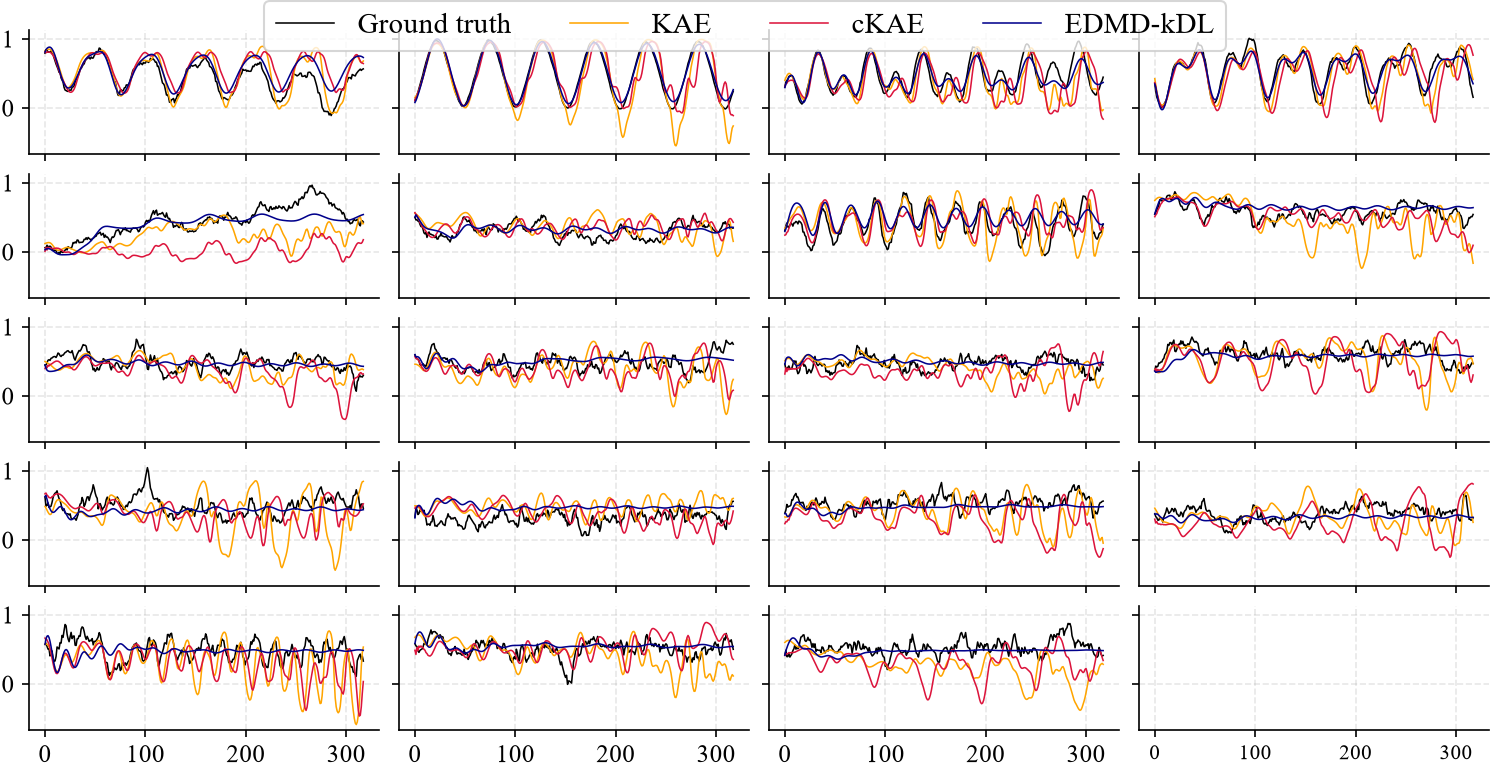

In [81]:
ncols = 4
nrows = int(np.ceil(dim/ncols))
fig, ax = plt.subplots(nrows, ncols, figsize=(ncols*2.5, nrows*1.), sharex=True, sharey=True, constrained_layout=True)
ax = ax.flatten()
for i in range(dim):
    ax[i].plot(Xtest_scaled[i, lag:], color='black', lw=0.75, label="Ground truth")
    #ax[i].plot(X_edmdrff_s[i, :], color='magenta',  label="EDMD-RFF")
    ax[i].plot(X_kae_s[i, :], color='orange', lw=0.75, label="KAE")
    ax[i].plot(X_ckae_s[i, :], color='crimson', lw=0.75, label="cKAE")
    ax[i].plot(X_edmd_s[i, :], color='darkblue', lw=0.75, label="EDMD-kDL")
    #ax[i].set_xlabel('iter', fontsize=12)
    #ax[i].set_title(rf'$\psi_{{{i+1}}}$', fontsize=12)
    ax[i].tick_params(axis='both', labelsize=12)

handles, labels = ax[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=len(labels), fontsize=14, bbox_to_anchor=(0.5,1.05))
plt.show()

### SINDy-SHRED

In [21]:
SEED = 0
set_seed(SEED)
# load data
load_X = load_data('SST')
n, m = load_X.shape

#==== configs
num_sensors = 250
sensor_locations = np.random.choice(m, size=num_sensors, replace=False)

lags = 52
train_length = 1000
validate_length = 30
dt = 1 / 52.0

latent_dim = 3
poly_order = 1
sindy_threshold = 0.05

#=== Initialize the SINDy-SHRED driver
model = SINDySHRED(
    latent_dim=latent_dim,
    poly_order=poly_order,
    include_sine=False,
    ode_order=1,  # 1st order ODE: z' = f(z)
    hidden_layers=2,
    l1=350,
    l2=400,
    dropout=0.1,
    batch_size=128,
    num_epochs=200,
    lr=1e-3,
    verbose=True,
    threshold=0.05,
    patience=5,
    sindy_regularization=10.0,
    optimizer="AdamW",
    thres_epoch=100,
    device=device,
)

print("SINDySHRED model initialized")

# Fit the model
# The driver automatically handles data preprocessing and training
model.fit(
    num_sensors=num_sensors,
    dt=dt,
    x_to_fit=load_X,
    lags=lags,
    train_length=train_length,
    validate_length=validate_length,
    sensor_locations=sensor_locations,
    seed=SEED,
)

(1400, 64800)
SINDySHRED model initialized
1 : tensor(0.0827, device='cuda:0', grad_fn=<AddBackward0>)
2 : tensor(0.0631, device='cuda:0', grad_fn=<AddBackward0>)
3 : tensor(0.0595, device='cuda:0', grad_fn=<AddBackward0>)
4 : tensor(0.0534, device='cuda:0', grad_fn=<AddBackward0>)
5 : tensor(0.0526, device='cuda:0', grad_fn=<AddBackward0>)
6 : tensor(0.0509, device='cuda:0', grad_fn=<AddBackward0>)
7 : tensor(0.0501, device='cuda:0', grad_fn=<AddBackward0>)
8 : tensor(0.0505, device='cuda:0', grad_fn=<AddBackward0>)
9 : tensor(0.0500, device='cuda:0', grad_fn=<AddBackward0>)
10 : tensor(0.0499, device='cuda:0', grad_fn=<AddBackward0>)
11 : tensor(0.0493, device='cuda:0', grad_fn=<AddBackward0>)
12 : tensor(0.0493, device='cuda:0', grad_fn=<AddBackward0>)
13 : tensor(0.0495, device='cuda:0', grad_fn=<AddBackward0>)
14 : tensor(0.0493, device='cuda:0', grad_fn=<AddBackward0>)
15 : tensor(0.0499, device='cuda:0', grad_fn=<AddBackward0>)
16 : tensor(0.0490, device='cuda:0', grad_fn=<AddBa

In [22]:
# Perform SINDy identification with automatic plot saving
model.sindy_identify(
    threshold=sindy_threshold, 
    plot_result=False
)

# Auto-tune threshold using nonparametric approach
# This computes least-squares solution first, then determines threshold range adaptively
best_threshold, tune_results = model.auto_tune_threshold(
    adaptive=True,           # Use nonparametric approach (default)
    scale_factor=0.3,        # Max threshold = 0.3 * max(|coefficients|)
    n_thresholds=10,         # Test 10 evenly spaced thresholds
    metric="bic", # Pick sparsest stable model
    verbose=True,
)

# Compute test reconstruction error using new API
test_recons = model.sensor_recon(data_type="test", return_scaled=False)
test_ground_truth = model._scaler.inverse_transform(
    model._test_data.Y.detach().cpu().numpy()
)

relative_error = model.relative_error(test_recons, test_ground_truth)
print(f"Test set relative reconstruction error: {relative_error:.4f}")

# Predict latent trajectories from end of training.
# IC = last training latent state; run for (validate_length + 1 + test_length) steps
# so that after trimming, output_sindy[t] aligns with test_Y[t].
offset = validate_length + 1
total_steps = offset + model._test_length
t_pred = np.arange(0, total_steps * model._dt, model._dt)
x_predict_full = model.sindy_predict(t=t_pred, split="train", init_from="last")
output_sindy_full = model.shred_decode(x_predict_full)

# Trim to align with test period (both arrays remain in scaled [0, 1] space)
x_predict = x_predict_full[offset:]
output_sindy = output_sindy_full[offset:]

print(f"SINDy prediction shape: {x_predict.shape}")
print(f"Decoded output shape: {output_sindy.shape}")

SINDy-derived dynamical equation (1st order):

(x0)' =  1.270 1 +  6.593 x0 + -1.504 x1 +  11.653 x2
(x1)' = -0.809 1 + -7.029 x0 + -1.140 x1 + -5.035 x2
(x2)' = -0.900 1 + -8.043 x0 + -1.402 x1 + -5.484 x2
Computing least-squares solution to determine threshold range...
Max |coefficient|: 11.6526
Max threshold (scale_factor=0.3): 3.4958
Testing 10 thresholds: [0.         0.38841896 0.77683792 1.16525688 1.55367584 1.9420948
 2.33051376 2.71893272 3.10735168 3.49577065]
Testing threshold=0.000... 

sparsity=12, stable, MSE=6.6525e-02
Testing threshold=0.388... sparsity=12, stable, MSE=6.6525e-02
Testing threshold=0.777... sparsity=12, stable, MSE=6.6525e-02
Testing threshold=1.165... sparsity=9, stable, MSE=2.4003e+02
Testing threshold=1.554... sparsity=6, stable, MSE=6.8154e-01
Testing threshold=1.942... sparsity=6, stable, MSE=6.8154e-01
Testing threshold=2.331... sparsity=6, stable, MSE=6.8154e-01
Testing threshold=2.719... sparsity=6, stable, MSE=6.8154e-01
Testing threshold=3.107... sparsity=6, stable, MSE=6.8154e-01
Testing threshold=3.496... sparsity=6, stable, MSE=6.8154e-01

Best threshold: 0.000 (sparsity=12, MSE=6.6525e-02)
SINDy-derived dynamical equation (1st order):

(x0)' =  1.270 1 +  6.593 x0 + -1.504 x1 +  11.653 x2
(x1)' = -0.809 1 + -7.029 x0 + -1.140 x1 + -5.035 x2
(x2)' = -0.900 1 + -8.043 x0 + -1.402 x1 + -5.484 x2
Test set relative reconstruction error: 0.0450
SINDy prediction shape: (318, 3)
Decoded output shape: (318, 44219)


### Sensor-level predictions

In [90]:
# unscale
X_edmdkdl = X_edmd_s * np.ptp(Xtrain, axis=1, keepdims=True) + Xtrain.min(axis=1, keepdims=True)
X_edmdrff = X_edmdrff_s * np.ptp(Xtrain, axis=1, keepdims=True) + Xtrain.min(axis=1, keepdims=True)
X_kae = X_kae_s * np.ptp(Xtrain, axis=1, keepdims=True) + Xtrain.min(axis=1, keepdims=True)
X_ckae = X_ckae_s * np.ptp(Xtrain, axis=1, keepdims=True) + Xtrain.min(axis=1, keepdims=True)

# map back to the scaled SST space
SST_edmdkdl_f = U[:, :r] @ X_edmdkdl
SST_edmdrff_f = U[:, :r] @ X_edmdrff
SST_kae_f = U[:, :r] @ X_kae
SST_ckae_f = U[:, :r] @ X_ckae

# add back the SST locations that were constant over the training phase
T_pred = SST_test.shape[1] - lag
SST_test_all = np.zeros((SST.shape[0], T_pred))
SST_test_all[~constant_rows] = SST_test_scaled[:,lag:]

SST_edmdkdl = np.zeros((SST.shape[0], T_pred))
SST_edmdkdl[~constant_rows] = SST_edmdkdl_f

SST_kae = np.zeros((SST.shape[0], T_pred))
SST_kae[~constant_rows] = SST_kae_f

SST_ckae = np.zeros((SST.shape[0], T_pred))
SST_ckae[~constant_rows] = SST_ckae_f


nrow, ncol = 5, 4
rng = np.random.default_rng(seed=42)
idx = rng.choice(SST.shape[0], nrow * ncol, replace=False)
fig, ax = plt.subplots(nrow, ncol, figsize=(ncol*2.25, nrow*1.25), sharex=True, sharey=True, constrained_layout=True)
ax = ax.flatten()
t_test = np.arange(T, T+M)

lw=0.85

for i, j in enumerate(idx):
    ax[i].plot(SST_test_all[j, :], color='black', lw=lw, label='Ground truth')
    ax[i].plot(output_sindy[:, j], '--', color='magenta', lw=lw, label='SINDy-SHRED')
    ax[i].plot(SST_kae[j, :], color='orange', lw=lw, label='KAE')
    ax[i].plot(SST_ckae[j, :], color='darkred', lw=lw, label='cKAE')
    ax[i].plot(SST_edmdkdl[j, :], color='blue', lw=lw, label='EDMD-kDL')
    #ax[i].set_title(f'Sensor {i+1}', fontsize=12)
    ax[i].grid(visible=False)
    ax[i].tick_params(axis='both', labelsize=14)
    ax[i].set_xticks([0, 150, 300])
    if i >= (nrow-1) * ncol:
        ax[i].set_xlabel('Time (in weeks)', fontsize=14)
    if i % ncol == 0:  
        ax[i].set_ylabel('SST', fontsize=14)
    

handles, labels = ax[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=len(labels), fontsize=14, 
           bbox_to_anchor=(0.5,1.07), frameon=False)
fig.savefig('figures/sst_prediction_sensors.pdf', format='pdf', bbox_inches='tight')
plt.close(fig)

### Prediction errors

**scaled**

In [91]:
fig = plt.figure(figsize=(4.5,1.75))
ref = SST_test_all
scale = np.linalg.norm(ref, axis=0)
lw = 1.0
plt.plot(np.linalg.norm(ref - output_sindy.T, axis=0) / scale[-model._test_length:], '--', lw=lw, color='magenta', label='SINDy-SHRED')
plt.plot(np.linalg.norm(ref - SST_kae, axis=0) / scale, lw=lw, color='orange', label='KAE')
plt.plot(np.linalg.norm(ref - SST_ckae, axis=0) / scale, lw=lw, color='darkred', label='cKAE')
plt.plot(np.linalg.norm(ref - SST_edmdkdl, axis=0) / scale, lw=lw, color='blue', label='EDMD-kDL')
plt.xlabel('Time (in weeks)', fontsize=12)
plt.ylabel('Prediction error', fontsize=12)
plt.tick_params(axis='both', labelsize=12)
plt.legend(loc = "upper left", ncols=4, bbox_to_anchor=(0., 1.2), fontsize=10, columnspacing=0.8, handlelength=1., handletextpad=0.2, frameon=False)
plt.grid(visible=False)

fig.savefig('figures/sst_prediction_error.pdf', format='pdf', bbox_inches='tight')
plt.close(fig)

**unscaled**

In [92]:
fig = plt.figure(figsize=(4.5,1.75))
ref = model._scaler.inverse_transform(SST_test_all.T)
scale = np.linalg.norm(ref, axis=1)
lw=1.0

error_sindyshred = np.linalg.norm(ref - model._scaler.inverse_transform(output_sindy), axis=1) / scale[-model._test_length:]
error_kae = np.linalg.norm(ref - model._scaler.inverse_transform(SST_kae.T), axis=1) / scale
error_ckae = np.linalg.norm(ref - model._scaler.inverse_transform(SST_ckae.T), axis=1) / scale
error_edmdkdl = np.linalg.norm(ref - model._scaler.inverse_transform(SST_edmdkdl.T), axis=1) / scale

plt.plot(error_sindyshred, '--', lw=lw, color='magenta', label='SINDy-SHRED')
plt.plot(error_kae, lw=lw, color='orange', label='KAE')
plt.plot(error_ckae, lw=lw, color='darkred', label='cKAE')
plt.plot(error_edmdkdl, lw=lw, color='blue', label='EDMD-kDL')
# 5% and 10% error lines
plt.axhline(0.05, color='gray', ls='--', lw=0.35)
plt.axhline(0.10, color='gray', ls='--', lw=0.35)

plt.xlabel('Time (in weeks)', fontsize=12)
plt.ylabel('Prediction error', fontsize=12)
plt.tick_params(axis='both', labelsize=12)
plt.legend(loc = "upper left", ncols=4, bbox_to_anchor=(0., 1.2), fontsize=10, columnspacing=0.8, handlelength=1.1, handletextpad=0.3, frameon=False)
plt.grid(visible=False)

fig.savefig('figures/sst_prediction_error_unscaled.pdf', format='pdf', bbox_inches='tight')
plt.close(fig)

In [93]:
# histogram of prediction errors
# subplots per method
methods = ['SINDy-SHRED', 'KAE', 'cKAE', 'EDMD-kDL']
errors = [error_sindyshred, error_kae, error_ckae, error_edmdkdl]
colors = ['magenta', 'orange', 'darkred', 'blue']
fig, axes = plt.subplots(1, len(methods), figsize=(len(methods)*2.5, 2), constrained_layout=True, sharey=True)
for i, (ax, method, error, color) in enumerate(zip(axes, methods, errors, colors)):
    ax.hist(error, bins=30, color=color, alpha=0.6,  density=True, cumulative=True, stacked=True)
    # 90% and 95% lines
    ax.axvline(np.percentile(error, 90), color='gray', ls='--', lw=0.75)
    ax.axvline(np.percentile(error, 97.5), color='black', ls='--', lw=0.75)
    ax.set_title(method, fontsize=12)
    ax.set_xlabel('Prediction error', fontsize=12)
    if i == 0:
        ax.set_ylabel('Cumulative density', fontsize=12)
    ax.tick_params(axis='both', labelsize=12)
    ax.grid(visible=False)
fig.savefig('figures/sst_prediction_error_histogram.pdf', format='pdf', bbox_inches='tight')
plt.close(fig)

In [94]:
print("max prediction errors for each method:")
print(f"SINDy-SHRED: {np.max(error_sindyshred) * 100:.1f}")
print(f"KAE: {np.max(error_kae) * 100:.1f}")
print(f"cKAE: {np.max(error_ckae) * 100:.1f}")
print(f"EDMD-kDL: {np.max(error_edmdkdl) * 100:.1f}")

max prediction errors for each method:
SINDy-SHRED: 11.8
KAE: 20.9
cKAE: 17.5
EDMD-kDL: 6.6


### Spatial comparison

In [95]:
import matplotlib.colors as colors

def plot_reconstruction_comparison(
    datasets,
    timesteps,
    labels,
    ref=None,
    error_plot=False,
    absolute_error=True,
    sst_locs=None,
    grid_shape=(180, 360),
    lat_range=None,
    lon_range=None,
    cmap="plasma",
    figsize=None,
    land_color="white",
):
    """Plot comparison between real and predicted spatial reconstructions.

    Parameters
    ----------
    datasets : list of array-like items
        Each item is of shape (n_samples, n_valid_features).
    timesteps : list
        List of timestep indices to visualize.
    labels : list
        List of labels associated with each dataset
    ref : array-like, optional
        Shape (n_samples, n_valid_features)
        Required when error_plot=True
    error_plot : bool, default False
        Whether to plot absolute errors with respect to `ref` or not.
    sst_locs : array-like, optional
        Flat indices of valid (ocean) spatial locations into the full grid.
        Locations NOT in sst_locs are masked out (e.g. land) and shown in `land_color`.
        If None, assumes all grid locations are valid.
    grid_shape : tuple, optional
        Shape of spatial grid for reshaping (lat, lon). Default is (180, 360).
    lat_range : tuple, optional
        Latitude index range for zooming (start, end). Default is full range.
    lon_range : tuple, optional
        Longitude index range for zooming (start, end). Default is full range.
    cmap : str, optional
        Colormap for real/predicted panels. Default "RdYlBu_r" (sequential-ish,
        works for absolute SST). Use a diverging map + diverging=True for anomalies.
    land_color : str, optional
        Color used for masked/invalid (e.g. land) locations.

    Returns
    -------
    fig : matplotlib.figure.Figure
    axes : array of matplotlib.axes.Axes
    """
    if error_plot:
        assert ref is not None

    if lat_range is None:
        lat_range = (0, grid_shape[0])
    if lon_range is None:
        lon_range = (0, grid_shape[1])

    nrows, ncols = len(datasets), len(timesteps)
    if figsize is None:
        figsize = (2.25 * ncols, 1.2 * nrows)

    fig, axes = plt.subplots(
        nrows, ncols, figsize=figsize, constrained_layout=True,
        sharex=True, sharey=True,
    )
    if ncols == 1:
        axes = axes.reshape(-1, 1)

    def to_grid(flat_row):
        """Embed a (possibly masked) flat data row into the full grid, zoomed."""
        if sst_locs is not None:
            full = np.full(grid_shape[0] * grid_shape[1], np.nan)
            full[sst_locs] = flat_row
        else:
            full = flat_row
        grid = full.reshape(grid_shape)
        grid = np.roll(grid, shift=grid_shape[1] // 2, axis=1)  # <-- added
        return np.ma.masked_invalid(
            grid[lat_range[0]:lat_range[1], lon_range[0]:lon_range[1]]
        )

    # Shared color scale across real + predicted panels
    norm_main = colors.TwoSlopeNorm(vcenter=15) 
    norm_err = colors.BoundaryNorm(np.arange(0, 4., 0.5), ncolors=256, extend='max') if absolute_error else colors.TwoSlopeNorm(vcenter=0, vmin=-2.5, vmax=2.5)
    norm = norm_err if error_plot else norm_main
    fontsize = 16 if nrows == 4 else 18
    

    cmap_obj = plt.get_cmap(cmap).copy()
    cmap_obj.set_bad(land_color)

    for i, data in enumerate(datasets):
        for j, t in enumerate(timesteps):
            snapshot_main = to_grid(data[t, :]) 
            if error_plot:
                snapshot_err = np.abs(to_grid(ref[t, :]) - to_grid(data[t, :])) if absolute_error else (to_grid(ref[t, :]) - to_grid(data[t, :]))
            plot = axes[i, j].imshow(
                snapshot_main if not error_plot else snapshot_err, aspect="auto", cmap=cmap_obj, norm=norm
            )
            axes[i, j].set_xticks([])
            axes[i, j].set_yticks([])
            if i == 0:
                axes[i, j].set_title(f"{t} weeks", fontsize=fontsize)  
            if j == 0:
                axes[i, j].set_ylabel(labels[i], fontsize=fontsize  )      
        

    cbar = fig.colorbar(plot, ax=axes, shrink=0.8, extend="max" if error_plot else "neither")
    cbar.ax.tick_params(labelsize=fontsize)

    return fig, axes

In [96]:
from sindy_shred.processdata import DATA_DIR
# Load SST location indices for visualization
load_X_full = sio.loadmat(os.path.join(DATA_DIR, 'SST_data.mat'))['Z'].T
mean_X = np.mean(load_X_full, axis=0)
sst_locs = np.where(mean_X != 0)[0]

# Compare reconstructions at selected timesteps
timesteps = [0, 50, 100, 200, 300]

# Use the test data ground truth
test_Y = model._test_data.Y.detach().cpu().numpy()

fig, axes = plot_reconstruction_comparison(
    datasets=[
        model._scaler.inverse_transform(test_Y),
        model._scaler.inverse_transform(SST_edmdkdl.T),
        model._scaler.inverse_transform(output_sindy),
        model._scaler.inverse_transform(SST_kae.T),
        model._scaler.inverse_transform(SST_ckae.T),
    ],
    timesteps = timesteps,
    labels=['Ground truth', 'EDMD-kDL', 'SINDy-SHRED', 'KAE', 'cKAE'],
    sst_locs=sst_locs,
    land_color='white',
    cmap='magma',
    figsize=(len(timesteps)*2.25, 1.5*5)
)

fig.savefig('figures/sst_prediction_maps.pdf', bbox_inches='tight')
plt.close()

In [97]:
fig, axes = plot_reconstruction_comparison(
    ref = model._scaler.inverse_transform(test_Y),
    datasets=[
        model._scaler.inverse_transform(SST_edmdkdl.T),
        model._scaler.inverse_transform(output_sindy),
        model._scaler.inverse_transform(SST_kae.T),
        model._scaler.inverse_transform(SST_ckae.T),
    ],
    timesteps = timesteps,
    labels=['EDMD-kDL', 'SINDy-SHRED', 'KAE', 'cKAE'],
    sst_locs=sst_locs,
    land_color='white',
    cmap='copper_r',
    error_plot=True,
    absolute_error=True,
    figsize=(len(timesteps)*2.25, 1.5*4)
)

fig.savefig('figures/sst_prediction_error_maps.pdf', bbox_inches='tight')
plt.close()


In [98]:
np.percentile(np.abs(model._scaler.inverse_transform(test_Y) - model._scaler.inverse_transform(SST_edmdkdl.T)), [2.5, 50, 97.5])

array([0.00397866, 0.36109839, 1.90536192])

In [99]:
# calculate mean absolute error for each method
mae_edmdkdl = np.mean(np.abs(model._scaler.inverse_transform(test_Y) - model._scaler.inverse_transform(SST_edmdkdl.T)))
mae_sindyshred = np.mean(np.abs(model._scaler.inverse_transform(test_Y) - model._scaler.inverse_transform(output_sindy)))
mae_kae = np.mean(np.abs(model._scaler.inverse_transform(test_Y) - model._scaler.inverse_transform(SST_kae.T)))
mae_ckae = np.mean(np.abs(model._scaler.inverse_transform(test_Y) - model._scaler.inverse_transform(SST_ckae.T)))

print(f"Mean Absolute Error (MAE) for each method:")
print(f"EDMD-kDL: {mae_edmdkdl:.2f}")
print(f"SINDy-SHRED: {mae_sindyshred:.2f}")
print(f"KAE: {mae_kae:.2f}")    
print(f"cKAE: {mae_ckae:.2f}")

Mean Absolute Error (MAE) for each method:
EDMD-kDL: 0.51
SINDy-SHRED: 0.67
KAE: 0.83
cKAE: 0.88


In [100]:
# calculate 95% absolute error interval for each method
mae_edmdkdl = np.percentile(np.abs(model._scaler.inverse_transform(test_Y) - model._scaler.inverse_transform(SST_edmdkdl.T)), [2.5, 50, 97.5])
mae_sindyshred = np.percentile(np.abs(model._scaler.inverse_transform(test_Y) - model._scaler.inverse_transform(output_sindy)), [2.5, 50, 97.5])
mae_kae = np.percentile(np.abs(model._scaler.inverse_transform(test_Y) - model._scaler.inverse_transform(SST_kae.T)), [2.5, 50, 97.5])
mae_ckae = np.percentile(np.abs(model._scaler.inverse_transform(test_Y) - model._scaler.inverse_transform(SST_ckae.T)), [2.5, 50, 97.5])

print(f"95% Absolute Error Interval (MAE) for each method:")
print(f"EDMD-kDL: lower={mae_edmdkdl[0]:.4f}, median={mae_edmdkdl[1]:.2f}, upper={mae_edmdkdl[2]:.2f}")
print(f"SINDy-SHRED: lower={mae_sindyshred[0]:.4f}, median={mae_sindyshred[1]:.2f}, upper={mae_sindyshred[2]:.2f}")
print(f"KAE: lower={mae_kae[0]:.4f}, median={mae_kae[1]:.2f}, upper={mae_kae[2]:.2f}")    
print(f"cKAE: lower={mae_ckae[0]:.4f}, median={mae_ckae[1]:.2f}, upper={mae_ckae[2]:.2f}")

95% Absolute Error Interval (MAE) for each method:
EDMD-kDL: lower=0.0040, median=0.36, upper=1.91
SINDy-SHRED: lower=0.0031, median=0.45, upper=2.82
KAE: lower=0.0069, median=0.51, upper=3.62
cKAE: lower=0.0066, median=0.56, upper=3.71


In [101]:
# calculate root mean square error for each method
rmse_edmdkdl = np.sqrt(np.mean((model._scaler.inverse_transform(test_Y) - model._scaler.inverse_transform(SST_edmdkdl.T))**2))
rmse_sindyshred = np.sqrt(np.mean((model._scaler.inverse_transform(test_Y) - model._scaler.inverse_transform(output_sindy))**2))
rmse_kae = np.sqrt(np.mean((model._scaler.inverse_transform(test_Y) - model._scaler.inverse_transform(SST_kae.T))**2))
rmse_ckae = np.sqrt(np.mean((model._scaler.inverse_transform(test_Y) - model._scaler.inverse_transform(SST_ckae.T))**2))

print(f"Root Mean Square Error (RMSE) for each method:")
print(f"EDMD-kDL: {rmse_edmdkdl:.2f}")
print(f"SINDy-SHRED: {rmse_sindyshred:.2f}")
print(f"KAE: {rmse_kae:.2f}")
print(f"cKAE: {rmse_ckae:.2f}")

Root Mean Square Error (RMSE) for each method:
EDMD-kDL: 0.73
SINDy-SHRED: 1.03
KAE: 1.36
cKAE: 1.35
